# SusFoodDetector 🤨: Food Adulteration Risk Predictor

This notebook demonstrates a structured machine learning pipeline designed to identify food adulteration risks across restaurants. We compare a baseline heuristic, a Linear Model (Logistic Regression), and a Gradient Boosting Tree model (LightGBM) to find out who is serving straight facts and who is capped.

## Step 0: Setup & Data
Runs locally or in Colab. If `data/` doesn't exist yet, it is generated with `generate_dataset.py` (seed 42, 8000 restaurants); in Colab you'll be asked to upload the script if it isn't there.

In [1]:
import sys, subprocess
from pathlib import Path

DATA_DIR = Path("data")
GENERATOR = Path("generate_dataset.py")
IN_COLAB = "google.colab" in sys.modules

# SHAP isn't always pre-installed
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)

if (DATA_DIR / "training_items_flat.csv").exists():
    print("Using existing data/ folder")
else:
    if not GENERATOR.exists() and IN_COLAB:
        from google.colab import files
        print("Please upload generate_dataset.py")
        files.upload()
    if not GENERATOR.exists():
        raise FileNotFoundError("generate_dataset.py must sit next to this notebook to build data/")
    result = subprocess.run(
        [sys.executable, str(GENERATOR), "--restaurants", "8000", "--seed", "42", "--out", str(DATA_DIR)],
        check=True, capture_output=True, text=True)
    print(result.stdout)

print("Files:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Using existing data/ folder
Files: ['dishes.csv', 'ingredients.csv', 'location_ingredient_stats.csv', 'locations.csv', 'menu_items.csv', 'restaurants.csv', 'training_items_flat.csv']


## Step 1: Libraries and Data Loading
We start by importing our essential data science and ML libraries, loading the structured dataset, and setting up the appropriate data splits.

In [2]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import shap
import joblib
import sklearn
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

# Set random seed for reproducibility
np.random.seed(42)

# Load dataset
df = pd.read_csv(DATA_DIR / "training_items_flat.csv")
print(f"Dataset loaded: {len(df)} rows")
print(f"Overall baseline positive rate (adulterated): {df['is_adulterated'].mean():.3%}")

Dataset loaded: 126851 rows
Overall baseline positive rate (adulterated): 17.874%


## Step 2: Feature Engineering & Splits
We separate our features from identifiers/labels and divide the data into training, validation, and test sets according to the preset `split` attribute (assigned per restaurant, so no restaurant appears in two splits).

In [3]:
# Define targets and drop metadata/leakage columns
y = df["is_adulterated"]
X = df.drop(columns=["is_adulterated", "adulterant_detected", "item_id",
                     "restaurant_id", "location_id", "split"])

# Identify and format categorical columns ("string" covers pandas 3, which no longer uses object for text)
cat_cols = list(X.select_dtypes(include=["object", "string"]).columns)
X[cat_cols] = X[cat_cols].astype("category")

# Define boolean indices for splits
tr = (df["split"] == "train")
va = (df["split"] == "val")
te = (df["split"] == "test")

print(f"Train size: {tr.sum()} | Val size: {va.sum()} | Test size: {te.sum()}")
print(f"{X.shape[1]} features, {len(cat_cols)} categorical")

Train size: 89959 | Val size: 17870 | Test size: 19022
50 features, 11 categorical


## Step 3: Model Training
We train two models on the training dataset:
1. **Logistic Regression (Linear Benchmark):** Requires categorical variables to be One-Hot Encoded and numeric variables scaled.
2. **LightGBM (Gradient Boosting Classifier):** Directly handles raw categorical features and uses early stopping on the validation set to prevent overfitting.

In [4]:
# --- 1. Logistic Regression Setup ---
X_oh = pd.get_dummies(X, columns=cat_cols).fillna(-1)
mu, sd = X_oh[tr].mean(), X_oh[tr].std() + 1e-9

print("Training Logistic Regression...")
lr = LogisticRegression(max_iter=2000, C=0.5)
lr.fit((X_oh[tr] - mu) / sd, y[tr])

# --- 2. LightGBM Setup ---
print("\nTraining LightGBM Classifier...")
model = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=63,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1
)

model.fit(
    X[tr], y[tr],
    eval_set=[(X[va], y[va])],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)]
)

Training Logistic Regression...



Training LightGBM Classifier...


Training until validation scores don't improve for 100 rounds


[200]	valid_0's auc: 0.90135	valid_0's binary_logloss: 0.26981


[400]	valid_0's auc: 0.902145	valid_0's binary_logloss: 0.267851


Early stopping, best iteration is:
[449]	valid_0's auc: 0.902448	valid_0's binary_logloss: 0.267561


,num_leaves,63
,learning_rate,0.03
,n_estimators,2000
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


## Step 4: Performance Evaluation (On Test Partition)
We generate predictions on our unseen test set and compare the models against a simplistic price-based rule.

In [5]:
# Predict probabilities on test partition
p_lr = lr.predict_proba((X_oh[te] - mu) / sd)[:, 1]
p_gbm = model.predict_proba(X[te])[:, 1]

def build_metrics_row(name, p):
    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y[te], p),
        "PR-AUC": average_precision_score(y[te], p)
    }

# Build comparative summary dataframe
metrics_summary = pd.DataFrame([
    build_metrics_row("Price-only rule (Heuristic)", -X[te]["price_ratio_to_peer_median"]),
    build_metrics_row("Logistic Regression", p_lr),
    build_metrics_row("LightGBM", p_gbm)
])

display(metrics_summary.round(4))
print(f"Random Class Baseline PR-AUC: {y[te].mean():.3f}")

,model,ROC-AUC,PR-AUC
0,Price-only rule (Heuristic),0.7392,0.4858
1,Logistic Regression,0.8975,0.7534
2,LightGBM,0.9025,0.7617


Random Class Baseline PR-AUC: 0.187


## Step 5: Optimization & Calibration (Threshold Tuning)
Using the validation set probabilities, we find the decision threshold that maximizes the F1-Score, then apply it to classify the test set.

In [6]:
# Predict validation probabilities
p_val = model.predict_proba(X[va])[:, 1]
prec, rec, thr = precision_recall_curve(y[va], p_val)

# Pick optimal threshold based on maximum F1-Score
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
thr_best = thr[f1_scores[:-1].argmax()]

# Map predictions to optimal threshold on the test set
pred_test = (p_gbm >= thr_best).astype(int)

print(f"Optimized Threshold picked on Validation: {thr_best:.3f}\n")
print("--- Test Set Classification Report ---")
print(classification_report(y[te], pred_test, digits=3))

print("--- Test Set Confusion Matrix ---")
print(confusion_matrix(y[te], pred_test))

Optimized Threshold picked on Validation: 0.309

--- Test Set Classification Report ---
              precision    recall  f1-score   support

           0      0.929     0.917     0.923     15474
           1      0.656     0.695     0.675      3548

    accuracy                          0.875     19022
   macro avg      0.793     0.806     0.799     19022
weighted avg      0.878     0.875     0.877     19022

--- Test Set Confusion Matrix ---
[[14183  1291]
 [ 1081  2467]]


## Step 6: Model Explainability with SHAP
We use SHAP values to visualize the global impacts of the features as well as local individual predictions.

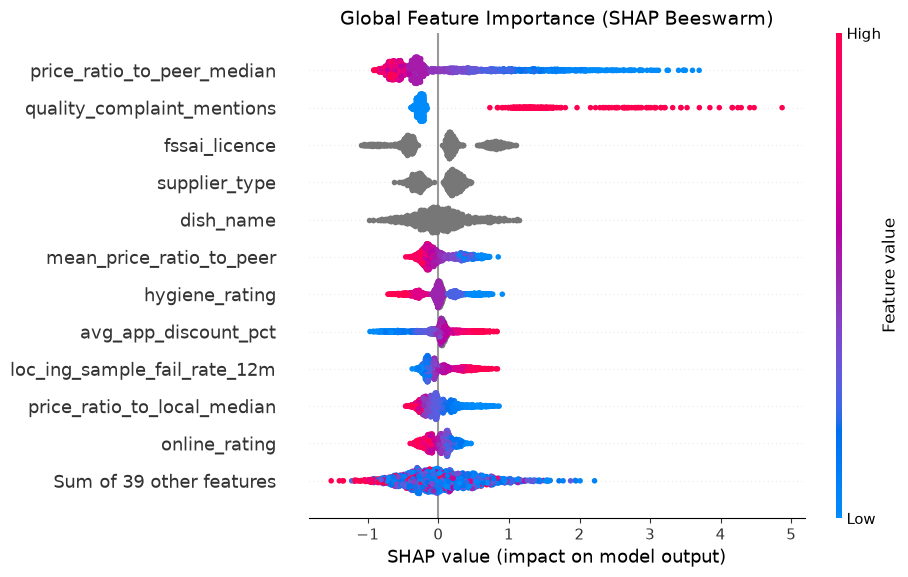

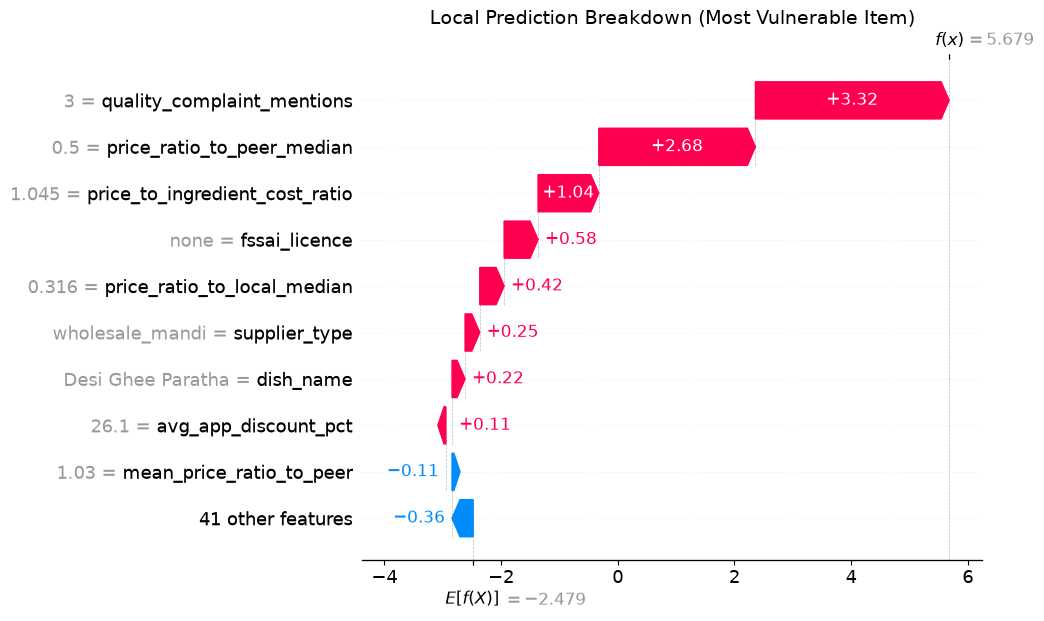

In [7]:
# Calculate SHAP values on a test sample
explainer = shap.TreeExplainer(model)
sample_test = X[te].sample(2000, random_state=42)
sv = explainer(sample_test)

# Adjust array dimensions if multi-class representation is outputted
if sv.values.ndim == 3:
    sv = sv[:, :, 1]

# Global Importance plot
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Global Feature Importance (SHAP Beeswarm)", fontsize=14)
plt.show()

# Local instance plot (Most extreme probability item)
high_risk_idx = int(np.argmax(model.predict_proba(sample_test)[:, 1]))
plt.figure(figsize=(10, 5))
shap.plots.waterfall(sv[high_risk_idx], max_display=10, show=False)
plt.title("Local Prediction Breakdown (Most Vulnerable Item)", fontsize=14)
plt.show()

## Step 7: Business Implementation & Risk Ranking
We map item predictions back to their restaurants to give inspectors a prioritised list.

**Which target to judge the ranking on:** about 75% of restaurants have at least one adulterated item, so on `any_adulterated` even a perfect ranking can only reach ~1.33× lift over random — "100% in the top 200" says little. We therefore also judge rankings on `risk_level == "high"` (≥ 25% of items adulterated, ~33% of restaurants), which is where inspections matter most.

**Two ways to score a restaurant:** its *riskiest item* (max) or its *average item* (mean). Max is better at "is anything here adulterated?"; mean is better at finding restaurants where adulteration is widespread.

In [8]:
rest_meta = pd.read_csv(DATA_DIR / "restaurants.csv")

# Aggregate item-level risk predictions up to restaurant level
test_predictions = df[te].assign(p=p_gbm)
restaurant_scores = (
    test_predictions.groupby("restaurant_id")["p"]
    .agg(max_item_score="max", mean_item_score="mean").reset_index()
    .merge(rest_meta[["restaurant_id", "restaurant_name", "restaurant_type", "any_adulterated", "risk_level"]],
           on="restaurant_id")
)
is_high = restaurant_scores["risk_level"] == "high"
any_rate, high_rate = restaurant_scores["any_adulterated"].mean(), is_high.mean()
print(f"Test restaurants: {len(restaurant_scores)} | any adulteration: {any_rate:.0%} "
      f"(max possible lift {1 / any_rate:.2f}x) | high risk: {high_rate:.0%} (max possible lift {1 / high_rate:.2f}x)\n")

# Compare the two restaurant scores
rows = []
for score in ["max_item_score", "mean_item_score"]:
    ranked = restaurant_scores.sort_values(score, ascending=False)
    row = {"rank by": score,
           "AUC (any)": roc_auc_score(restaurant_scores["any_adulterated"], restaurant_scores[score]),
           "AUC (high risk)": roc_auc_score(is_high, restaurant_scores[score])}
    for k in (50, 100, 200):
        top_high = ranked.head(k)["risk_level"] == "high"
        row[f"top {k}: % high risk"] = top_high.mean()
        row[f"top {k}: % of high risk caught"] = top_high.sum() / is_high.sum()
    rows.append(row)
display(pd.DataFrame(rows).set_index("rank by").T.round(3))

# Calculate Inspector Hit Rates using the mean item score
restaurant_rankings = restaurant_scores.sort_values("mean_item_score", ascending=False)
for k in (50, 100, 200):
    hit_rate = (restaurant_rankings.head(k)["risk_level"] == "high").mean()
    print(f"Inspect top {k:3d} restaurants: {hit_rate:4.0%} high risk vs {high_rate:4.0%} random ({hit_rate / high_rate:.2f}x lift)")

print("\n--- Top 10 High-Risk Establishments for Prioritized Inspection ---")
display(restaurant_rankings.head(10))

Test restaurants: 1203 | any adulteration: 75% (max possible lift 1.33x) | high risk: 33% (max possible lift 3.06x)



rank by,max_item_score,mean_item_score
AUC (any),0.906,0.871
AUC (high risk),0.875,0.939
top 50: % high risk,0.900,1.000
top 50: % of high risk caught,0.115,0.127
top 100: % high risk,0.870,0.990
top 100: % of high risk caught,0.221,0.252
top 200: % high risk,0.785,0.960
top 200: % of high risk caught,0.399,0.489


Inspect top  50 restaurants: 100% high risk vs  33% random (3.06x lift)
Inspect top 100 restaurants:  99% high risk vs  33% random (3.03x lift)
Inspect top 200 restaurants:  96% high risk vs  33% random (2.94x lift)

--- Top 10 High-Risk Establishments for Prioritized Inspection ---


,restaurant_id,max_item_score,mean_item_score,restaurant_name,restaurant_type,any_adulterated,risk_level
197,R01519,0.959369,0.892608,Desi Darbar,street_stall,1,high
78,R00772,0.996996,0.873326,Amrit Mithai Bhandar,sweet_shop,1,high
829,R05602,0.989377,0.866888,Urban Palace,cloud_kitchen,1,high
513,R03423,0.984604,0.859179,Taj Darbar,street_stall,1,high
779,R05203,0.992042,0.854829,Madras Tadka,street_stall,1,high
1101,R07328,0.990675,0.852607,Kwality Sweets,cloud_kitchen,1,high
883,R05905,0.995018,0.839784,Lakshmi Tadka,dhaba,1,high
588,R03896,0.992956,0.830640,Shree Treats,qsr,1,high
268,R01958,0.972904,0.825590,Amrit Grand,sweet_shop,1,high
37,R00420,0.978570,0.824458,New Bites,casual_dining,1,high


## Step 8: Save the Model
Saves the trained LightGBM model **together with** the decision threshold and the exact feature list, so whoever loads it can score new rows the same way. Also writes the booster as plain text (`.txt`), which loads in any LightGBM version.

To use it later:
```python
bundle = joblib.load("sus_food_detector_lgbm.pkl")
X_new = new_df[bundle["features"]].copy()
X_new[bundle["categorical_features"]] = X_new[bundle["categorical_features"]].astype("category")
p = bundle["model"].predict_proba(X_new)[:, 1]
flagged = p >= bundle["threshold"]
```

In [9]:
bundle = {
    "model": model,
    "threshold": float(thr_best),
    "features": list(X.columns),
    "categorical_features": cat_cols,
    "restaurant_score": "mean of item probabilities (see Step 7)",
    "test_metrics": {"roc_auc": float(roc_auc_score(y[te], p_gbm)),
                     "pr_auc": float(average_precision_score(y[te], p_gbm))},
    "versions": {"lightgbm": lgb.__version__, "sklearn": sklearn.__version__, "pandas": pd.__version__},
}
joblib.dump(bundle, "sus_food_detector_lgbm.pkl")
model.booster_.save_model("sus_food_detector_lgbm.txt")

# Sanity check: reload and confirm it reproduces the test predictions
loaded = joblib.load("sus_food_detector_lgbm.pkl")
p_check = loaded["model"].predict_proba(X[te][loaded["features"]])[:, 1]
assert np.allclose(p_check, p_gbm), "reloaded model doesn't match"
print(f"Saved model: {len(loaded['features'])} features, threshold {loaded['threshold']:.3f}, "
      f"test ROC-AUC {loaded['test_metrics']['roc_auc']:.4f} — reload check passed")

Saved model: 50 features, threshold 0.309, test ROC-AUC 0.9025 — reload check passed


## Step 9: NLP — Inferring Ingredients from Dish Names
The model scores an item through `primary_ingredient`, `ingredient_grams_est`, `veg_nonveg` and `dish_category`, but a real menu only lists names, and many names don't say what's inside: **Haleem** is mutton + wheat + lentils + **ghee**, **Dal Makhani** is **butter** + cream, **Rasgulla** is chhena (**paneer**). `ingredient_nlp.py` turns raw menu text into those columns:

1. **Knowledge base**: ~200 Indian dishes (340+ names and aliases) with their ingredients. Matching happens after spelling normalisation (*makhni → makhani*, *murgh → chicken*, *biriyani → biryani*) and per-token fuzzy correction (*Panner Tikka Masaala*). Names made of several parts are combined: *Rabri Jalebi*, *Paneer Biryani* (the named paneer replaces the default chicken).
2. **Keywords**: ingredient words in the name (*paneer, ghee, makhani, kesar, fried, …*) for dishes not in the knowledge base.
3. **Claude (optional)**: names nothing above resolves (e.g. *Kosha Mangsho*) go to Claude, constrained to the same ingredient vocabulary and cached in `ingredient_llm_cache.json`. It's enabled when `ANTHROPIC_API_KEY` is set.

In [10]:
import os
from pathlib import Path

NLP_MODULE = Path("ingredient_nlp.py")
if not NLP_MODULE.exists() and IN_COLAB:
    from google.colab import files
    print("Please upload ingredient_nlp.py")
    files.upload()
from ingredient_nlp import IngredientInferer, expand_tracked_ingredients

# Claude is only asked about names the knowledge base and keywords can't resolve
USE_CLAUDE = bool(os.environ.get("ANTHROPIC_API_KEY"))
nlp = IngredientInferer(use_llm=USE_CLAUDE)
print(f"Knowledge base: {len(nlp.kb)} dish names/aliases | Claude fallback: {'on' if USE_CLAUDE else 'off'}")

examples = ["Hyderabadi Haleem (Full)", "Dal Makhni", "Mutton Nihari", "Rasgulla", "Kesar Badam Milk",
            "Panner Tikka Masaala", "Paneer Biryani", "Egg Biryani", "Rabri Jalebi", "Butter Roti",
            "Murgh Makhani", "Kosha Mangsho"]
display(pd.DataFrame([{
    "menu text": p.query,
    "matched dish": " + ".join(p.matched_dishes),
    "source": p.source,
    "veg_nonveg": p.veg_nonveg,
    "category": p.dish_category,
    "primary_ingredient": p.primary_ingredient,
    "risky ingredients": ", ".join(p.tracked_ingredients),
    "all ingredients": ", ".join(p.ingredients),
} for p in nlp.infer_many(examples)]))

Knowledge base: 346 dish names/aliases | Claude fallback: off


,menu text,matched dish,source,veg_nonveg,category,primary_ingredient,risky ingredients,all ingredients
0,Hyderabadi Haleem (Full),Haleem,kb_partial,nonveg,main,ghee,ghee,"mutton, wheat, pulses, ghee"
1,Dal Makhni,Dal Makhani,kb,veg,main,butter,butter,"butter, pulses, cream"
2,Mutton Nihari,Nihari,kb_partial,nonveg,main,ghee,ghee,"mutton, ghee, wheat"
3,Rasgulla,Rasgulla,kb,veg,dessert,paneer,paneer,"paneer, sugar"
4,Kesar Badam Milk,Badam Milk,kb_partial,veg,beverage,saffron,"saffron, milk","saffron, milk, nuts"
5,Panner Tikka Masaala,Paneer Tikka Masala,kb,veg,main,paneer,"paneer, butter, curd","paneer, butter, cream, curd"
6,Paneer Biryani,Chicken Biryani (paneer instead of chicken),kb_partial,veg,rice,paneer,"paneer, ghee","paneer, rice, ghee"
7,Egg Biryani,Chicken Biryani (egg instead of chicken),kb_partial,nonveg,rice,ghee,ghee,"egg, rice, ghee"
8,Rabri Jalebi,Rabri + Jalebi,kb_partial,veg,dessert,milk,"milk, edible_oil","milk, sugar, edible_oil, maida"
9,Butter Roti,Roti,kb_partial,veg,bread,butter,butter,"butter, wheat"


**Sanity check.** If we throw away the ingredient columns in our dataset and rebuild them from `dish_name` alone, the model should score the test set exactly as before.

In [11]:
# Sanity check: drop the ingredient columns and recover them from the dish name alone
ing_cols = ["primary_ingredient", "ingredient_grams_est", "veg_nonveg", "dish_category"]
dish_table = df[["dish_name"] + ing_cols].drop_duplicates("dish_name").reset_index(drop=True)
recovered = nlp.enrich(dish_table[["dish_name"]])
exact = (recovered[ing_cols].values == dish_table[ing_cols].values).all(axis=1)
print(f"Recovered all four columns for {exact.sum()}/{len(dish_table)} training dishes from the name alone")

# Re-score the test set using only NLP-derived ingredient columns
lookup = recovered.set_index("dish_name")[ing_cols]
X_nlp = X[te].copy()
for c in ing_cols:
    vals = df.loc[te, "dish_name"].map(lookup[c])
    X_nlp[c] = pd.Categorical(vals, categories=X[c].cat.categories) if c in cat_cols else vals
print(f"Test ROC-AUC with NLP-derived columns: {roc_auc_score(y[te], model.predict_proba(X_nlp)[:, 1]):.4f} "
      f"(original {roc_auc_score(y[te], p_gbm):.4f})")

Recovered all four columns for 93/93 training dishes from the name alone


Test ROC-AUC with NLP-derived columns: 0.9025 (original 0.9025)


**Scoring a new menu.** A dish can carry several risky ingredients (Paneer Makhani = paneer + butter), so we score the item once per ingredient, with that ingredient's local market stats, and combine: P(any adulterated) = 1 − ∏(1 − pᵢ). Dishes the training data never saw (Haleem, Nihari) have no peer-price comparison, so their price ratio is left missing and the model leans on the restaurant and ingredient signals instead.

In [12]:
# Score a new menu for an existing test restaurant: one prediction per risky ingredient in each dish
item_cols = ["dish_name", "dish_category", "veg_nonveg", "primary_ingredient", "ingredient_grams_est",
             "menu_price_inr", "est_ingredient_cost_inr", "peer_group_size", "peer_median_price_inr",
             "price_ratio_to_peer_median", "local_median_price_inr", "local_listing_count",
             "price_ratio_to_local_median", "price_to_ingredient_cost_ratio", "quality_complaint_mentions"]
loc_ing_stats = pd.read_csv(DATA_DIR / "location_ingredient_stats.csv")

# a mughlai test restaurant the model rates as low risk, so a suspicious item stands out
mean_p = pd.Series(p_gbm, index=df.index[te]).groupby(df.loc[te, "restaurant_id"]).mean()
mughlai = df[te & (df["primary_cuisine"] == "mughlai") & (df["restaurant_type"] == "casual_dining")]
rest = mughlai[mughlai["restaurant_id"] == mean_p[mughlai["restaurant_id"].unique()].idxmin()].iloc[0]
context = rest.drop(item_cols + [c for c in rest.index if c.startswith("loc_ing_")])
new_menu = pd.DataFrame({
    "dish_name": ["Hyderabadi Haleem (Full)", "Dal Makhni", "Mutton Nihari", "Paneer Biryani",
                  "Kesar Badam Milk", "Rasgulla (2 pcs)", "Butter Roti", "Kosha Mangsho",
                  "Paneer Makhani"],                         # last one deliberately underpriced
    "menu_price_inr": [300, 240, 360, 250, 110, 80, 45, 340, 140],
})
menu = nlp.enrich(new_menu).assign(**context.to_dict())
rows = expand_tracked_ingredients(menu, loc_ing_stats)

# Peer prices exist only for dishes the training data has seen (by canonical name, same city + type)
rows["dish_name"] = rows["nlp_matched_dish"].where(rows["nlp_matched_dish"].isin(X["dish_name"].cat.categories))
peers = df.groupby(["city", "restaurant_type", "dish_name"])["menu_price_inr"].agg(["median", "size"])
key = pd.MultiIndex.from_frame(rows[["city", "restaurant_type", "dish_name"]])
rows["peer_median_price_inr"] = peers["median"].reindex(key).values
rows["peer_group_size"] = peers["size"].reindex(key).values
rows["price_ratio_to_peer_median"] = rows["menu_price_inr"] / rows["peer_median_price_inr"]
rows["quality_complaint_mentions"] = 0

X_new = rows.reindex(columns=X.columns)
for c in cat_cols:
    X_new[c] = pd.Categorical(X_new[c], categories=X[c].cat.categories)
rows["p"] = model.predict_proba(X_new)[:, 1]

# A dish is clean only if every risky ingredient in it is: P(any) = 1 - prod(1 - p_i)
per_item = rows.groupby("item_index").apply(lambda g: pd.Series({
    "p_any_adulterated": 1 - (1 - g["p"]).prod(),
    "riskiest_ingredient": g.loc[g["p"].idxmax(), "primary_ingredient"],
    "ingredient_scores": ", ".join(f"{i} {p:.2f}" for i, p in zip(g["primary_ingredient"], g["p"])),
}), include_groups=False)
report = menu[["dish_name", "menu_price_inr", "nlp_matched_dish", "veg_nonveg", "nlp_source"]].join(per_item)
report["flagged"] = report["p_any_adulterated"] >= thr_best
print(f"Restaurant {rest['restaurant_id']} ({rest['restaurant_type']}, {rest['city']}) — "
      "dishes with no tracked risky ingredient (or unresolved names) have no score")
display(report.sort_values("p_any_adulterated", ascending=False).round(3))

Restaurant R04584 (casual_dining, Hyderabad) — dishes with no tracked risky ingredient (or unresolved names) have no score


,dish_name,menu_price_inr,nlp_matched_dish,veg_nonveg,nlp_source,p_any_adulterated,riskiest_ingredient,ingredient_scores,flagged
8,Paneer Makhani,140,Paneer Butter Masala,veg,kb,0.779,paneer,"paneer 0.62, butter 0.42",True
3,Paneer Biryani,250,Chicken Biryani (paneer instead of chicken),veg,kb_partial,0.561,paneer,"paneer 0.35, ghee 0.32",True
5,Rasgulla (2 pcs),80,Rasgulla,veg,kb,0.386,paneer,paneer 0.39,True
0,Hyderabadi Haleem (Full),300,Haleem,nonveg,kb_partial,0.328,ghee,ghee 0.33,True
2,Mutton Nihari,360,Nihari,nonveg,kb_partial,0.328,ghee,ghee 0.33,True
6,Butter Roti,45,Roti,veg,kb_partial,0.225,butter,butter 0.22,False
4,Kesar Badam Milk,110,Badam Milk,veg,kb_partial,0.022,saffron,"saffron 0.01, milk 0.01",False
1,Dal Makhni,240,Dal Makhani,veg,kb,0.010,butter,butter 0.01,False
7,Kosha Mangsho,340,,NaN,unknown,NaN,NaN,NaN,False
